### WEEK 4 CAPSTONE: **PREDICTING INTERNSHIP SELECTION OUTCOMES**

**Author:** Maryam Fatima  |  **Program:** NextGenLearners Data Science Internship

**Goal:** Use applicant information to explore which factors are associated with being selected for the NextGenLearners internship, and communicate the findings honestly to a non-technical audience.

> ⚠️ **Note:** Four of the features used in this notebook are **simulated**, not real historical data. Results show how the method works, not how selection really happens.

## CONTENTS
| Section | What it covers |
|---|---|
| **Day 1** | Load the data and add four simulated features |
| **Day 2** | Prepare the data for a model (encoding and target) |
| **Day 3** | Train/test split and training the model |
| **Day 4** | Evaluate the model and discuss its limitations |
| **Day 5** | Which features mattered most |
| **Day 6** | Executive Summary |

### DAY 1: **SET UP AND EXTEND THE DATASET**

**Today's Steps:** Import the libraries, load the cleaned Week 1 data, and add four simulated applicant features, clearly documented.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

### Step 2: Load the Cleaned Dataset
We reuse the cleaned applicant data from Week 1 (duplicates removed, text standardized, missing values handled). `Phone` is read as text because phone numbers are identifiers, not quantities.

In [2]:
df = pd.read_csv('applicants_cleaned.csv', dtype={"Phone": str})
print(df.shape)

(71, 7)


In [3]:
print(df["Status"].value_counts())
df.head()


Status
Under Review    34
Selected        23
Rejected        14
Name: count, dtype: int64


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Hassan Malik,hassan.malik19@gmail.com,03235456272,Data Science,FAST NUCES,27-05-2026,Under Review
1,Danish Khan,danish.khan44@gmail.com,03352156902,Mobile App Development,COMSATS University,16-08-2026,Under Review
2,Omar Sheikh,omar.sheikh47@gmail.com,03281170307,Data Science,University of Karachi,20-08-2026,Under Review
3,Bilal Iqbal,bilal.iqbal2@gmail.com,03255437923,Graphic Design,IBA Karachi,22-02-2026,Rejected
4,Talha Qureshi,talha.qureshi72@gmail.com,03241368085,Graphic Design,IBA Karachi,22-08-2026,Rejected


### Step 2b: Simulating New Features

⚠️ **Honesty note:** The four features below are **simulated**, not real historical data. They were generated by code, and three of them were deliberately set up to be somewhat higher for selected applicants. Any pattern the model finds therefore reflects the assumptions built into this simulation, **not** real behaviour at NextGenLearners. In a real deployment, this information would have to be collected from actual applications (a skills field, a portfolio URL field, etc.) before the model could be trusted.

| Feature | Type | How it was simulated |
|---|---|---|
| num_skills_listed | Number (1–8) | Pure random, unrelated to selection |
| has_portfolio | Yes/No | ~70% Yes for selected, ~35% for others |
| prior_hackathon_participation | Yes/No | ~45% Yes for selected, ~25% for others |
| statement_quality_score | Number (1–10) | Centered around 7 for selected, 5 for others |

`np.random.seed(42)` makes the "random" numbers identical on every run, so results are reproducible.

In [4]:
np.random.seed(42)
n = len(df)
is_selected = (df["Status"] == "Selected")

df["num_skills_listed"] = np.random.randint(1, 9, size=n)

df["has_portfolio"] = np.where(
    is_selected,
    np.random.choice(["Yes", "No"], size=n, p=[0.70, 0.30]),
    np.random.choice(["Yes", "No"], size=n, p=[0.35, 0.65]),
)

df["prior_hackathon_participation"] = np.where(
    is_selected,
    np.random.choice(["Yes", "No"], size=n, p=[0.45, 0.55]),
    np.random.choice(["Yes", "No"], size=n, p=[0.25, 0.75]),
)

scores = np.random.normal(loc=np.where(is_selected, 7, 5), scale=1.5, size=n)
df["statement_quality_score"] = np.clip(scores.round(), 1, 10).astype(int)

df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Hassan Malik,hassan.malik19@gmail.com,03235456272,Data Science,FAST NUCES,27-05-2026,Under Review,7,No,No,5
1,Danish Khan,danish.khan44@gmail.com,03352156902,Mobile App Development,COMSATS University,16-08-2026,Under Review,4,Yes,Yes,5
2,Omar Sheikh,omar.sheikh47@gmail.com,03281170307,Data Science,University of Karachi,20-08-2026,Under Review,5,No,No,5
3,Bilal Iqbal,bilal.iqbal2@gmail.com,03255437923,Graphic Design,IBA Karachi,22-02-2026,Rejected,7,No,Yes,8
4,Talha Qureshi,talha.qureshi72@gmail.com,03241368085,Graphic Design,IBA Karachi,22-08-2026,Rejected,3,No,No,4


**What this cell did:**

Added four simulated columns to every applicant.

Three (`has_portfolio`, `prior_hackathon_participation`, `statement_quality_score`) were made slightly more favourable for selected applicants. `num_skills_listed` is pure random noise with no link to selection.

In [5]:
print(df.shape)
print(df.isnull().sum())
df.groupby("Status")[["num_skills_listed", "statement_quality_score"]].mean().round(2)

(71, 11)
Applicant Name                   0
Email                            0
Phone                            0
Domain Applied                   0
University                       0
Application Date                 2
Status                           0
num_skills_listed                0
has_portfolio                    0
prior_hackathon_participation    0
statement_quality_score          0
dtype: int64


,num_skills_listed,statement_quality_score
Status,,
Rejected,5.07,4.64
Selected,4.78,7.39
Under Review,4.47,5.41


**Check results:**

The dataset now has 71 rows and 11 columns. The only missing values are 2 application dates carried over from Week 1. They won't be used as a feature, so they don't matter here. Selected applicants average a statement score of about 7.4, against about 4.6 for rejected ones, as designed. Average skills listed is about the same across groups (roughly 4.5–5), which is expected because that feature is random.

### Day 2: **Feature Preparation**

**Goal:** The goal is to turn everything into numbers, because the model can’t read “Yes” or “Web Development”.

### Step 3: Feature Preparation
Machine learning models only work with numbers. This step:
1. Keeps only applicants with a final decision (removes "Under Review")
2. Converts Yes/No columns to 1/0
3. Creates the target column (what we want to predict)
4. One-hot encodes the Domain column
5. Selects the final input columns

### A: filter, convert Yes/No, create target

In [6]:
df_model = df[df["Status"] != "Under Review"].copy()

df_model["has_portfolio"] = df_model["has_portfolio"].map({"Yes" : 1, "No" : 0})
df_model["prior_hackathon_participation"] = df_model["prior_hackathon_participation"].map({"Yes" : 1, "No" : 0})

df_model["target"] = (df_model["Status"] == "Selected").astype(int)
# In machine learning, the thing you’re predicting is called the target.

print(df_model.shape)
print(df_model["target"].value_counts())
df_model[["Status", "has_portfolio", "prior_hackathon_participation", "target"]].head()



(37, 12)
target
1    23
0    14
Name: count, dtype: int64


,Status,has_portfolio,prior_hackathon_participation,target
3,Rejected,0,1,0
4,Rejected,0,0,0
6,Selected,0,0,1
8,Rejected,1,0,0
9,Rejected,0,0,0


**What this did:** Applicants still "Under Review" were removed because they have no final outcome to learn from. Yes/No columns became 1/0, and a `target` column was created (1 = Selected, 0 = Rejected). The remaining dataset has **37 rows: 23 Selected and 14 Rejected.**

### B: one-hot encoding

In [7]:
df_encoded = pd.get_dummies(df_model, columns=["Domain Applied"], drop_first=True, dtype=int)
# pd.get_dummies replaces the Domain column with one 0/1 column per domain.

df_encoded.head()

,Applicant Name,Email,Phone,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,target,Domain Applied_Digital Marketing,Domain Applied_Graphic Design,Domain Applied_Mobile App Development,Domain Applied_Web Development
3,Bilal Iqbal,bilal.iqbal2@gmail.com,03255437923,IBA Karachi,22-02-2026,Rejected,7,0,1,8,0,0,1,0,0
4,Talha Qureshi,talha.qureshi72@gmail.com,03241368085,IBA Karachi,22-08-2026,Rejected,3,0,0,4,0,0,1,0,0
6,Hira Malik,hira.malik41@gmail.com,03005148725,NED University,NaN,Selected,5,0,0,5,1,0,0,0,1
8,Hassan Ansari,hassan.ansari50@gmail.com,03495747930,NED University,22-03-2026,Rejected,7,1,0,4,0,0,0,0,0
9,Ahmed Hussain,ahmed.hussain21@gmail.com,03481131249,FAST NUCES,21-03-2026,Rejected,2,0,0,4,0,1,0,0,0


**Why one-hot encoding:** Domains have no natural order, so numbering them 1, 2, 3 would wrongly imply one domain is "more" than another. Each domain gets its own 0/1 column instead. `drop_first=True` automatically drops the first domain alphabetically (Data Science), which becomes the default: an applicant with 0 in every domain column is a Data Science applicant. This avoids redundant information and is standard practice.

**Output:** `Domain Applied` was replaced by 4 columns (Digital Marketing, Graphic Design, Mobile App Development, Web Development). `df_encoded` has 15 columns.

### C: final feature set

In [8]:
feature_columns = [
    "num_skills_listed",
    "has_portfolio",
    "prior_hackathon_participation",
    "statement_quality_score",
]+[col for col in df_encoded.columns if col.startswith("Domain Applied_")]

X = df_encoded[feature_columns]
y = df_encoded["target"]

print(X.shape)
print(y.shape)
X.head()

(37, 8)
(37,)


,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,Domain Applied_Digital Marketing,Domain Applied_Graphic Design,Domain Applied_Mobile App Development,Domain Applied_Web Development
3,7,0,1,8,0,1,0,0
4,3,0,0,4,0,1,0,0
6,5,0,0,5,0,0,0,1
8,7,1,0,4,0,0,0,0
9,2,0,0,4,1,0,0,0


**Output:** `X` has 37 rows and 8 columns (4 applicant features + 4 domain columns), and `y` holds the 37 outcomes (1 = Selected, 0 = Rejected). The safety check confirms there are no missing values and every column is numeric.

In [9]:
print("Missing values in X:", X.isnull().sum().sum())
print(X.dtypes)

Missing values in X: 0
num_skills_listed                        int64
has_portfolio                            int64
prior_hackathon_participation            int64
statement_quality_score                  int64
Domain Applied_Digital Marketing         int64
Domain Applied_Graphic Design            int64
Domain Applied_Mobile App Development    int64
Domain Applied_Web Development           int64
dtype: object


**Features used:** the 4 simulated applicant features plus the domain columns.

**Features deliberately excluded:**
- *Applicant Name, Email, Phone*: identifiers with no real predictive meaning, and inappropriate to feed into a selection model.
- *Status*: this is the answer itself. Including it would let the model "cheat" (data leakage).
- *University*: excluded to avoid the model learning institutional favouritism, which is a bias risk discussed in the limitations.
- *Application Date*: administrative, not a meaningful signal, and has 2 missing values.

### Day 3: **Train/Test Split and Training the Model**

### Step 4: Train/Test Split
The data is split into a **training set** (80%), which the model learns from, and a **test set** (20%), which the model never sees during training. Testing on unseen applicants shows whether the model learned real patterns or just memorized the training data, like grading a student on questions they haven't studied before.

`random_state=42` makes the split reproducible. `stratify=y` keeps the share of Selected applicants about the same in both sets. With so few rows, this stops a lucky or unlucky split from putting almost all one outcome in the test set.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


print("Training Rows:", len(X_train))       #80%
print("Test Rows:", len(X_test))            #20%

labels = {1: "Selected", 0: "Rejected"}

print("Training Outcomes:\n", y_train.map(labels).value_counts().rename_axis("Outcome"))
print("\nTest Outcomes:\n", y_test.map(labels).value_counts().rename_axis("Outcome"))


Training Rows: 29
Test Rows: 8
Training Outcomes:
 Outcome
Selected    18
Rejected    11
Name: count, dtype: int64

Test Outcomes:
 Outcome
Selected    5
Rejected    3
Name: count, dtype: int64


**Output:** The 37 applicants were split into **29 for training and 8 for testing**. The test set is very small, so one wrong prediction changes accuracy by about 12 percentage points. Results should therefore be treated as illustrative, not reliable.

### Step 5: Train the Model
**Logistic Regression** is used because it is the standard, simple model for yes/no outcomes (Selected or Not Selected). It calculates a probability of selection for each applicant from their features, and its results are easy to interpret, which matters for explaining the findings later.

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
comparison

,Actual,Predicted
0,1,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,0
6,0,0
7,1,1


**Output:** The model was trained on 29 applicants and then predicted outcomes for the 8 unseen test applicants. The table compares each real outcome (Actual) with the model's prediction (Predicted), where 1 = Selected and 0 = Rejected.

### DAY 4: **EVALUATE THE MODEL**

### 1. ACCURACY
Accuracy is the percentage of test applicants the model predicted correctly (Selected or Not Selected). **Limitation:** with small or imbalanced data, accuracy alone can mislead. A model that always guessed "Selected" would score well without learning anything, so the "always guess Selected" score is shown as a baseline to beat.

In [12]:
accuracy = accuracy_score(y_test, y_pred)
baseline = y_test.mean()

print(f"Accuracy: {accuracy:.2%}")
print(f"Baseline (always guess selected): {baseline:.2%}")


Accuracy: 62.50%
Baseline (always guess selected): 62.50%


**OUTPUT:**

The model's accuracy is **62.5%** (5 of 8 test applicants predicted correctly). However, 5 of the 8 test applicants were Selected, so always guessing "Selected" would also score 62.5%. The model has **not clearly beaten** simple guessing, which is why a second metric is needed.

### 2. PRECISION, RECALL AND THE CONFUSION MATRIX

Precision: 100.00%
Recall: 40.00%


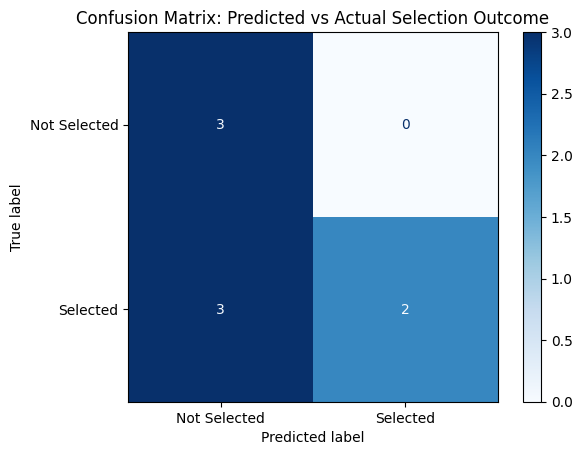

In [13]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Selected", "Selected"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix: Predicted vs Actual Selection Outcome")
plt.show()

**Rows show the real outcome and columns show the prediction; the diagonal holds correct predictions.**

### PRECISION, RECALL AND CONFUSION MATRIX
- **Precision (100%):** Of the 2 applicants the model predicted would be Selected, both really were. It made no false promises. This is based on only 2 predictions, so it should not be over-trusted.
- **Recall (40%):** Of the 5 applicants who were actually Selected, the model caught only 2. It **missed 3 strong candidates**.
- **Confusion matrix:** The model correctly identified 3 Not Selected applicants and 2 Selected applicants. It wrongly predicted Not Selected for 3 applicants who were really Selected, and it did not wrongly flag any rejected applicant as Selected.

**In plain terms:** the model is cautious. It rarely says "Selected", and when it does it is right, but it overlooks most of the people who actually were selected.

### MODEL LIMITATIONS
- **Small, partly simulated data:** Only 37 applicants had a final decision, and 4 features were artificially generated, not real historical behaviour. The patterns the model finds reflect how the simulation was built.
- **Tiny test set:** With 8 test applicants, one prediction changes accuracy by about 12 percentage points. A different split could give noticeably different results. These numbers illustrate the method and are not a guarantee of real-world performance.
- **Risk of bias:** A model learns from past decisions. If past selections favoured certain universities or backgrounds for reasons unrelated to merit, the model could learn and repeat that unfairness.
- **Decision support only:** This model should help reviewers prioritise, never replace human judgment.

### DAY 5: **Which Features Mattered Most**
**Logistic Regression** gives every feature a **coefficient**, a number showing how that feature pushes the prediction:
- A **positive** coefficient means that as the feature goes up, the applicant is more likely to be predicted "Selected".
- A **negative** coefficient means the opposite.
- A coefficient close to **zero** means the feature had little influence.

*Domain columns are compared with the default domain, Data Science.*

In [14]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

coefficients

,Feature,Coefficient
3,statement_quality_score,1.097021
7,Domain Applied_Web Development,0.815659
1,has_portfolio,0.483727
4,Domain Applied_Digital Marketing,-0.007665
2,prior_hackathon_participation,-0.283265
0,num_skills_listed,-0.286405
6,Domain Applied_Mobile App Development,-0.377492
5,Domain Applied_Graphic Design,-1.066319


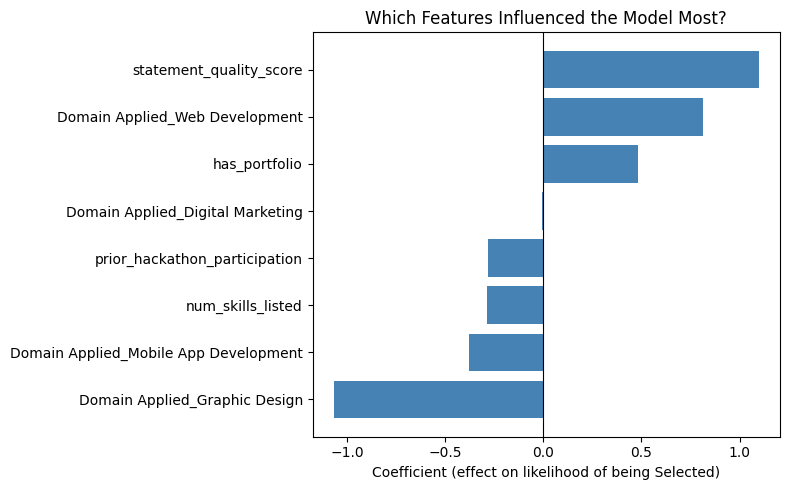

In [15]:
plot_data = coefficients.sort_values(by="Coefficient")

plt.figure(figsize=(8, 5))
plt.barh(plot_data["Feature"], plot_data["Coefficient"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (effect on likelihood of being Selected)")
plt.title("Which Features Influenced the Model Most?")
plt.tight_layout()
plt.show()

# **SANITY CHECK**

In [16]:
pd.crosstab(df_model["Status"], df_model["prior_hackathon_participation"], normalize="index").round(2)

prior_hackathon_participation,0,1
Status,,
Rejected,0.64,0.36
Selected,0.65,0.35


**OUTPUT:** Among applicants with a final decision, 35% of Selected and 36% of Rejected applicants had prior hackathon experience, essentially no difference. The simulation was designed so that selected applicants were more likely to have hackathon experience (45% vs 25%), but with only 23 Selected and 14 Rejected applicants, random variation was large enough to hide that difference. The model's small negative coefficient for this feature therefore reflects chance in a small sample, not a real effect.

In [17]:
coefficients["Scaled Effect"] = coefficients["Coefficient"] * X_train[coefficients["Feature"]].std().values
coefficients.sort_values(by="Scaled Effect", ascending=False)

,Feature,Coefficient,Scaled Effect
3,statement_quality_score,1.097021,2.244134
7,Domain Applied_Web Development,0.815659,0.313561
1,has_portfolio,0.483727,0.238866
4,Domain Applied_Digital Marketing,-0.007665,-0.002946
6,Domain Applied_Mobile App Development,-0.377492,-0.116998
2,prior_hackathon_participation,-0.283265,-0.139877
5,Domain Applied_Graphic Design,-1.066319,-0.485025
0,num_skills_listed,-0.286405,-0.628318


**WHAT "SCALED EFFECT" MEANS:** Features are measured on different scales (a portfolio is 0 or 1, while skills run from 1 to 8), so raw coefficients can't be compared fairly. The Scaled Effect multiplies each coefficient by how much that feature typically varies between applicants, showing the effect of a typical change. By this measure, `statement_quality_score` stands far ahead of every other feature.

### INTERPRETATION
In this model, **statement_quality_score** was by far the strongest positive predictor of selection, followed by **has_portfolio**. Applicants in Web Development were predicted as more likely to be selected than Data Science applicants, and Graphic Design applicants less likely, but each domain has only a handful of applicants, so these differences are weak. **num_skills_listed** and **prior_hackathon_participation** showed small effects.

**IMPORTANT:** Several features were simulated, and the simulation was built so that some of them relate to selection. This is therefore **what the model learned from this dataset**, not a real finding about how NextGenLearners selects applicants. With only 29 training applicants, small coefficients (for example the negative value for skills, which was generated purely at random) are most likely chance and should not be interpreted. These findings would need to be checked against real historical data.

### DAY 6: **EXECUTIVE SUMMARY AND README**

In [18]:
print("Applicants in dataset:", len(df))
print("With a final decision:", len(df_model))
print(f"Accuracy: {accuracy:.1%}   Precision: {precision:.1%}   Recall: {recall:.1%}")
print("Strongest feature:", coefficients.sort_values("Scaled Effect", ascending=False).iloc[0]["Feature"])

Applicants in dataset: 71
With a final decision: 37
Accuracy: 62.5%   Precision: 100.0%   Recall: 40.0%
Strongest feature: statement_quality_score


## EXECUTIVE SUMMARY

**WHAT WE DID:** We built a simple prediction model using applicant data to explore which factors are associated with being selected for the NextGenLearners internship program. Of 71 applicants, 37 had a final decision (selected or rejected). The model learned from 29 of them and was then tested on 8 it had never seen.

**WHAT WE FOUND:** The model correctly predicted the outcome for about 63% of the test applicants (5 of 8). When it predicted that someone would be selected, it was right both times, but it found only 2 of the 5 applicants who were actually selected. Because 5 of the 8 test applicants were selected, simply guessing "selected" for everyone would have scored the same, so the model is **not yet better than guessing**. The strongest factors associated with selection were **the strength of the applicant's written statement** and **whether they provided a portfolio (GitHub) link**.

**IMPORTANT CAVEATS:** This analysis used a small, partly simulated dataset. Several factors (skills listed, portfolio, hackathon history and statement quality) were artificially generated for this exercise rather than taken from real application records, so these findings show how the method works, not how NextGenLearners really selects people. With so few applicants, results could change noticeably with a different split of the data. Before using anything like this for real decisions, NextGenLearners would need to collect this information consistently from real applications and test the model on a much larger set. The model should only ever support human reviewers, never replace them, especially because it could unintentionally repeat biases from past decisions.
